In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import torch
from torch import nn
from pathlib import Path

In [2]:
data_path = Path.cwd().parent / "data/raw/bloomberg/"
out_path = Path.cwd().parent / "data/processed"
device = "cuda" if torch.cuda.is_available() else "cpu"

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10,
    "lines.linewidth": 1.6, "legend.frameon": False,
})

In [3]:
def load_tenor(tenor):
    d = pd.read_csv(data_path / f"ovdv_impvol/SPX_IMPVOL_{tenor}.csv", parse_dates=True, index_col=0)
    d.columns = d.columns.str.extract(r"IMPVOL_([\d.]+)%")[0].astype(float)
    d.columns.name = "moneyness"
    return d

BAD_DATES = ["2022-09-20"]  # see 01_eda_series, step 2c

iv = load_tenor("30DAY")
iv.loc[BAD_DATES] = np.nan

TEST_START = "2021-01-01"
test = iv.index[iv.index >= TEST_START]
y = iv.loc[test]
pred_rw = iv.shift(1).loc[test]

# inputs: forward-fill only uses the past, so it does not leak; targets keep the NaN
iv_in = iv.ffill()
target = iv.diff().shift(-1)

In [4]:
def make_windows(L):
    """X[t]: last L days up to t, channels (daily change, level); shape (days, 2, L, 9)."""
    level, change = iv_in.to_numpy(), iv_in.diff().to_numpy()
    X = np.full((len(iv), 2, L, iv.shape[1]), np.nan, dtype=np.float32)
    for i in range(L, len(iv)):
        X[i, 0] = change[i - L + 1 : i + 1]
        X[i, 1] = level[i - L + 1 : i + 1]
    return X

In [5]:
class SmileCNN(nn.Module):
    """2D convolutions over (time, moneyness), average over time, linear head to the 9 changes."""

    def __init__(self, channels=16, linear=False):
        super().__init__()
        act = nn.Identity() if linear else nn.GELU()
        self.conv = nn.Sequential(
            nn.Conv2d(2, channels, 3, padding=1), act,
            nn.Conv2d(channels, channels, 3, padding=1), act,
        )
        self.head = nn.Linear(channels * 9, 9)
        # zero output at init: the untrained network is persistence
        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x):
        return self.head(self.conv(x).mean(dim=2).flatten(1))

In [6]:
def fit_cnn(X, Y, seed, linear=False, val_frac=0.15, epochs=300, patience=30, batch=64):
    """Huber loss, AdamW, early stopping on the last val_frac of the training window."""
    torch.manual_seed(seed)
    n_val = max(int(val_frac * len(X)), 20)
    Xt, Yt, Xv, Yv = X[:-n_val], Y[:-n_val], X[-n_val:], Y[-n_val:]
    model = SmileCNN(linear=linear).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.HuberLoss(delta=1.0)
    best, best_state, wait = np.inf, None, 0
    for epoch in range(epochs):
        model.train()
        for b in torch.randperm(len(Xt)).split(batch):
            opt.zero_grad()
            loss_fn(model(Xt[b]), Yt[b]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val = loss_fn(model(Xv), Yv).item()
        if val < best:
            best, best_state, wait = val, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, epoch

In [7]:
def predict_cnn(L=20, linear=False, seeds=5):
    """Walk-forward, expanding window, refit on the first day of each month; average of `seeds` networks."""
    X, Y = make_windows(L), target.to_numpy(dtype=np.float32)
    ok = np.isfinite(X).all(axis=(1, 2, 3)) & np.isfinite(Y).all(axis=1)
    pred = pd.DataFrame(index=test, columns=iv.columns, dtype=float)
    epochs = []
    for month, days in pd.Series(test, index=test).groupby(test.to_period("M")):
        start = days.index[0]
        train = ok & (target.index < start)
        train[:-1] &= iv.index[1:] < start  # the target day t+1 must also be before the refit date
        Xtr, Ytr = X[train], Y[train]

        # scaling fitted on the training window only
        sd_change, mu_level, sd_level, sd_y = Xtr[:, 0].std(), Xtr[:, 1].mean(), Xtr[:, 1].std(), Ytr.std()
        def scale(x):
            x = x.copy()
            x[:, 0] /= sd_change
            x[:, 1] = (x[:, 1] - mu_level) / sd_level
            return torch.tensor(x, device=device)

        Xte = scale(X[iv.index.get_indexer(days.index) - 1])  # forecast for t uses the window ending at t-1
        out = []
        for seed in range(seeds):
            model, ep = fit_cnn(scale(Xtr), torch.tensor(Ytr / sd_y, device=device), seed, linear)
            epochs.append(ep)
            with torch.no_grad():
                out.append(model(Xte).cpu().numpy() * sd_y)
        pred.loc[days.index] = pred_rw.loc[days.index].to_numpy() + np.mean(out, axis=0)
    return pred, np.array(epochs)

In [8]:
preds = pd.read_pickle(out_path / "smile30_baseline_preds.pkl")
cnn_epochs = {}
for name, kw in {
    "cnn_L20": {"L": 20},
    "cnn_L20_linear": {"L": 20, "linear": True},
    "cnn_L5": {"L": 5},
}.items():
    preds[name], cnn_epochs[name] = predict_cnn(**kw)

pd.DataFrame({k: pd.Series(v).describe() for k, v in cnn_epochs.items()}).loc[["mean", "min", "max"]].round(0)

,cnn_L20,cnn_L20_linear,cnn_L5
mean,82.0,74.0,52.0
min,30.0,30.0,30.0
max,298.0,239.0,145.0


In [9]:
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def predict_ridge_window(L=5, level=True):
    """Ridge on the flattened CNN input window: same samples, refit dates and expanding window as the CNN."""
    X, Y = make_windows(L), target.to_numpy()
    if not level:
        X = X[:, :1]
    X = X.reshape(len(X), -1)
    ok = np.isfinite(X).all(axis=1) & np.isfinite(Y).all(axis=1)
    pred = pd.DataFrame(index=test, columns=iv.columns, dtype=float)
    alphas = {}
    for month, days in pd.Series(test, index=test).groupby(test.to_period("M")):
        start = days.index[0]
        train = ok & (iv.index < start)
        train[:-1] &= iv.index[1:] < start
        model = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 6, 29))).fit(X[train], Y[train])
        pred.loc[days.index] = pred_rw.loc[days.index].to_numpy() + model.predict(X[iv.index.get_indexer(days.index) - 1])
        alphas[month] = model[-1].alpha_
    return pred, pd.Series(alphas)


ridge_alphas = {}
for name, kw in {
    "ridge_win5": {"L": 5},
    "ridge_win5_no_level": {"L": 5, "level": False},
    "ridge_win20": {"L": 20},
}.items():
    preds[name], ridge_alphas[name] = predict_ridge_window(**kw)

pd.DataFrame(ridge_alphas).describe().loc[["min", "50%", "max"]]

,ridge_win5,ridge_win5_no_level,ridge_win20
min,562.341325,562.341325,10000.00000
50%,1000.000000,562.341325,13891.39705
max,3162.277660,3162.277660,17782.79410


In [10]:
valid = y.notna().all(axis=1)
for p in preds.values():
    valid &= p.notna().all(axis=1)

errors = {name: (y - p)[valid] for name, p in preds.items()}
print(f"Evaluated days: {valid.sum()} ({y.index[valid][0]:%Y-%m-%d} to {y.index[valid][-1]:%Y-%m-%d})")

Evaluated days: 1440 (2021-01-04 to 2026-10-07)


In [11]:
def r2_oos(e, e_ref):
    return 1 - (e**2).to_numpy().sum() / (e_ref**2).to_numpy().sum()

shown = ["persistence", "ar1_rolling252_huber", "ridge_lag1_rolling252", "pca_var_rolling252",
         "ridge_win5_no_level", "ridge_win5", "ridge_win20", "cnn_L20_linear", "cnn_L20", "cnn_L5"]
summary = pd.DataFrame({
    name: {
        "mae": errors[name].abs().to_numpy().mean(),
        "rmse": np.sqrt((errors[name]**2).to_numpy().mean()),
        "mae_vs_rw": errors[name].abs().to_numpy().mean() / errors["persistence"].abs().to_numpy().mean() - 1,
        "r2_oos_vs_rw": r2_oos(errors[name], errors["persistence"]),
    }
    for name in shown
}).T
summary.round(4)

,mae,rmse,mae_vs_rw,r2_oos_vs_rw
persistence,0.9059,1.4527,0.0000,0.0000
ar1_rolling252_huber,0.8975,1.4354,-0.0093,0.0237
ridge_lag1_rolling252,0.9053,1.4443,-0.0006,0.0116
pca_var_rolling252,0.9155,1.4477,0.0106,0.0069
ridge_win5_no_level,0.9239,1.4586,0.0199,-0.0081
ridge_win5,0.9156,1.4440,0.0107,0.0120
ridge_win20,0.9153,1.4485,0.0104,0.0059
cnn_L20_linear,0.8921,1.4304,-0.0152,0.0305
cnn_L20,0.8922,1.4361,-0.0151,0.0228
cnn_L5,0.8886,1.4225,-0.0190,0.0412


In [12]:
mae_by_moneyness = pd.DataFrame({name: errors[name].abs().mean(axis=0) for name in shown}).T
mae_by_moneyness.round(3)

moneyness,80.0,90.0,95.0,97.5,100.0,102.5,105.0,110.0,120.0
persistence,1.052,0.976,0.981,0.995,0.988,0.877,0.695,0.457,1.133
ar1_rolling252_huber,1.044,0.966,0.975,0.990,0.983,0.871,0.691,0.454,1.103
ridge_lag1_rolling252,1.051,0.975,0.980,0.995,0.990,0.879,0.697,0.461,1.119
pca_var_rolling252,1.065,0.988,0.994,1.008,1.002,0.892,0.710,0.469,1.112
ridge_win5_no_level,1.064,0.985,0.996,1.012,1.005,0.898,0.728,0.516,1.110
ridge_win5,1.048,0.975,0.987,1.002,0.997,0.890,0.722,0.506,1.112
ridge_win20,1.048,0.975,0.987,1.002,0.995,0.888,0.719,0.496,1.128
cnn_L20_linear,1.028,0.952,0.966,0.982,0.975,0.864,0.690,0.463,1.109
cnn_L20,1.032,0.953,0.962,0.977,0.973,0.864,0.687,0.459,1.124
cnn_L5,1.022,0.946,0.959,0.976,0.971,0.863,0.691,0.465,1.104


In [13]:
mae_by_year = pd.DataFrame({name: errors[name].abs().mean(axis=1).groupby(errors[name].index.year).mean() for name in shown})
mae_by_year.T.round(3)

date,2021,2022,2023,2024,2025,2026
persistence,1.024,1.163,0.732,0.710,0.984,0.807
ar1_rolling252_huber,0.999,1.165,0.726,0.711,0.976,0.792
ridge_lag1_rolling252,0.991,1.186,0.737,0.718,0.985,0.798
pca_var_rolling252,1.012,1.191,0.745,0.720,0.999,0.810
ridge_win5_no_level,1.027,1.228,0.751,0.738,0.970,0.810
ridge_win5,1.021,1.196,0.752,0.741,0.963,0.802
ridge_win20,1.025,1.173,0.747,0.731,0.993,0.803
cnn_L20_linear,1.005,1.142,0.740,0.706,0.960,0.781
cnn_L20,1.008,1.141,0.733,0.701,0.961,0.792
cnn_L5,0.997,1.143,0.724,0.714,0.962,0.772


In [14]:
def diebold_mariano(e_ref, e, loss, maxlags=5):
    dl = loss(e_ref).mean(axis=1) - loss(e).mean(axis=1)
    res = sm.OLS(dl.to_numpy(), np.ones(len(dl))).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    return res.tvalues[0], res.pvalues[0]

losses = {"squared": lambda e: e**2, "absolute": lambda e: e.abs()}
dm = pd.DataFrame({
    (ref, name, loss_name): dict(zip(["t_stat", "p_value"], diebold_mariano(errors[ref], errors[name], loss)))
    for ref in ["persistence", "ar1_rolling252_huber", "ridge_win5"]
    for name in ["ridge_win5", "cnn_L5", "cnn_L20_linear"]
    if name != ref
    for loss_name, loss in losses.items()
}).T
dm.round(3)

t_stat  p_value
persistence          ridge_win5     squared    0.503    0.615
                                    absolute  -1.326    0.185
                     cnn_L5         squared    1.185    0.236
                                    absolute   2.340    0.019
                     cnn_L20_linear squared    1.349    0.177
                                    absolute   2.164    0.030
ar1_rolling252_huber ridge_win5     squared   -0.750    0.453
                                    absolute  -3.254    0.001
                     cnn_L5         squared    0.594    0.552
                                    absolute   1.323    0.186
                     cnn_L20_linear squared    0.410    0.682
                                    absolute   0.963    0.335
ridge_win5           cnn_L5         squared    1.277    0.202
                                    absolute   3.722    0.000
                     cnn_L20_linear squared    1.524    0.128
                                    absolute   3.720    0.000

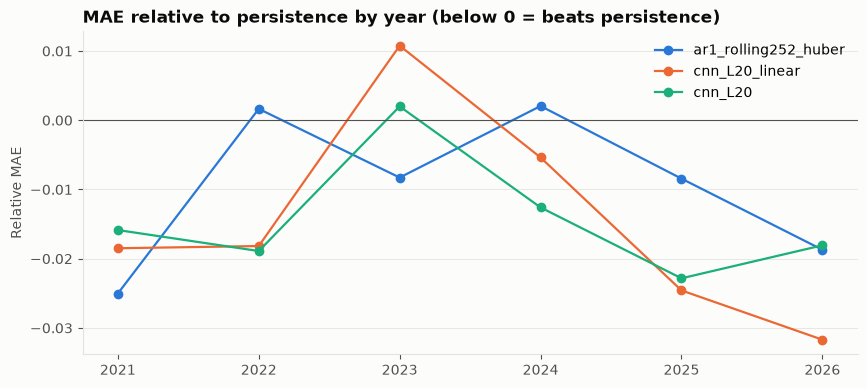

In [15]:
best = ["ar1_rolling252_huber", "cnn_L20_linear", "cnn_L20"]
rel = mae_by_year[best].div(mae_by_year["persistence"], axis=0) - 1

fig, ax = plt.subplots(figsize=(10, 4.2))
for name, color in zip(best, COLORS):
    ax.plot(rel.index, rel[name], marker="o", color=color, label=name)
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_title("MAE relative to persistence by year (below 0 = beats persistence)")
ax.set_ylabel("Relative MAE")
ax.legend()
plt.show()

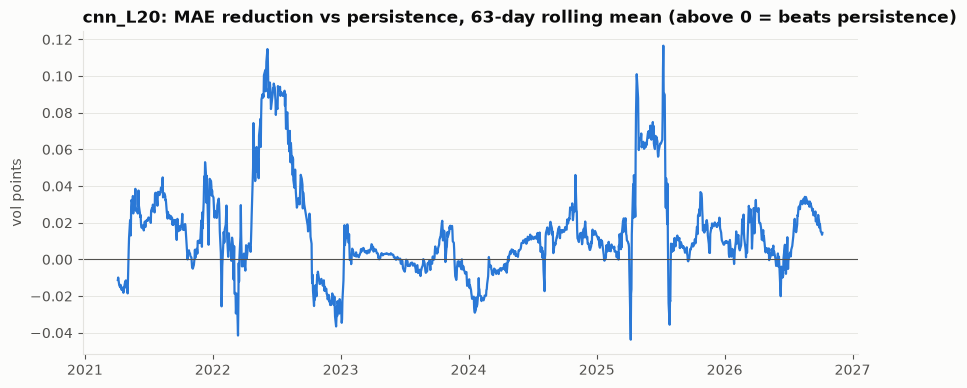

In [16]:
gain = (errors["persistence"].abs().mean(axis=1) - errors["cnn_L20"].abs().mean(axis=1)).rolling(63).mean()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(gain.index, gain, color=COLORS[0])
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_title("cnn_L20: MAE reduction vs persistence, 63-day rolling mean (above 0 = beats persistence)")
ax.set_ylabel("vol points")
plt.show()